# PCA, PCR y PLS — NHANES (Práctica I)

**Objetivo:** aplicar reducción de dimensión (PCA) y regresión sobre componentes (PCR, PLS) al dataset de salud cardiometabólica de NHANES, y comparar con Ridge/Lasso como referencia.

**Dataset:** `data/nhanes_cardiometabolic_clean.csv` (10.739 adultos × 73 columnas).

**Decisiones clave:**
- **Variable respuesta:** `sbp` (presión arterial sistólica). También puedes usar `bmi`.
- **Panel "sin ayunas":** se excluyen `ldl`, `triglycerides`, `glucose_fasting` e `insulin` (~55 % de NA, solo submuestra en ayunas) para conservar ~7.600 casos completos. Para usar todo el panel, añádelas a `predictors` y asume ~3.500 casos.
- **`globulin` fuera:** es combinación lineal exacta (`total_protein − albumin`).
- **Log de las asimétricas:** `hs_crp`, `ggt`, `alt`, `cpk`, `trig_serum`.
- **Escalado dentro del `Pipeline`:** `StandardScaler` se reajusta solo con los datos de entrenamiento de cada fold (sin fuga de información).

## 1. Importaciones y carga de datos

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.cross_decomposition import PLSRegression
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.metrics import mean_squared_error, r2_score

RANDOM_STATE = 42
plt.rcParams["figure.figsize"] = (10, 6)

In [2]:
df = pd.read_csv("data/nhanes_cardiometabolic_clean.csv")
print("Dimensiones:", df.shape)
df.head()

Dimensiones: (10739, 73)


,seqn,cycle,psu,strata,wt_mec,wt_fasting,fasting_subsample,age,sex,race_eth,...,baso_pct,rbc,hemoglobin,hematocrit,mcv,mch,mchc,rdw,platelets,mpv
0,83732,2015-2016,1,125,67814.753703,NaN,False,62,male,nh_white,...,0.5,4.93,15.2,44.7,90.8,30.8,34.0,13.9,181.0,8.3
1,83733,2015-2016,1,125,12641.212964,27361.171665,True,53,male,nh_white,...,1.8,4.89,17.5,49.7,101.8,35.8,35.1,13.4,170.0,9.6
2,83734,2015-2016,1,131,6287.919409,12735.546850,True,78,male,nh_white,...,0.9,4.18,12.4,37.9,90.8,29.6,32.6,14.7,223.0,9.0
3,83735,2015-2016,1,131,51039.317254,NaN,False,56,female,nh_white,...,0.9,4.54,12.8,40.1,88.3,28.2,31.9,13.1,280.0,9.1
4,83736,2015-2016,2,126,9117.368109,19089.755435,True,42,female,nh_black,...,0.2,4.16,12.1,36.5,87.8,29.1,33.2,12.3,275.0,7.7


## 2. Selección de variables y transformaciones

Se elige un **conjunto de variables cuantitativas** (antropometría + biomarcadores), que es lo que pide la sección de PCA de la práctica.

Observaciones:

- La multicolinealidad es **intencionada**: `total_chol`–`chol_serum` (r≈0.99), `hemoglobin`–`hematocrit` (0.97), `sodium`–`osmolality` (0.81), `ast`–`alt` (0.73). PCA sirve precisamente para resumir estas variables correlacionadas en pocas componentes.
- Las variables con colas largas se transforman con `log(1+x)` antes de estandarizar, para reducir el peso de los valores extremos.
- `PCA` de sklearn **solo centra** (no escala); por eso se usa `StandardScaler` antes.

In [3]:
predictors = [
    # antropometría y demografía
    "age", "bmi", "waist", "pulse",
    # lípidos, glucosa e inflamación (sin ayunas)
    "total_chol", "hdl", "hba1c", "hs_crp",
    # hígado
    "albumin", "total_protein",
    "alt", "ast", "alp", "ggt", "ldh", "bilirubin", "cpk",
    # riñón
    "bun", "creatinine", "uric_acid",
    # electrolitos y minerales
    "sodium", "potassium", "chloride", "bicarbonate",
    "calcium", "phosphorus", "iron", "osmolality",
    # bioquímica sin ayuno
    "glucose_serum", "chol_serum", "trig_serum",
    # hemograma
    "wbc", "rbc", "hemoglobin", "hematocrit", "mcv", "mch", "mchc", "rdw",
    "platelets", "mpv",
    "lymph_pct", "mono_pct", "neut_pct", "eos_pct", "baso_pct",
]

skewed = ["hs_crp", "ggt", "alt", "cpk", "trig_serum"]  # colas largas -> log
response = "sbp"

data = df[predictors + [response]].copy()
for c in skewed:
    data[c] = np.log1p(data[c])   # log(1+x): maneja ceros (p. ej. hs_crp == 0)

data = data.dropna()
X = data[predictors]
y = data[response]

print("Casos completos:", X.shape)
print("Predictores:", X.shape[1])
print("Respuesta:", response)

Casos completos: (9075, 46)
Predictores: 46
Respuesta: sbp


## 3. PCA (no supervisado)

Se ajusta PCA sobre **todos los casos completos**. Es un análisis descriptivo (no hay variable respuesta ni selección de modelo), así que no hay riesgo de fuga de información al usar todos los datos.

`pca.components_` es la matriz de rotación Φ (filas = direcciones, columnas = variables). La varianza de cada componente `Zj` es el autovalor de `(1/(n−1))·X̃ᵗX̃`, es decir, los valores singulares al cuadrado entre `(n−1)`; en sklearn es `pca.explained_variance_` y la proporción `pca.explained_variance_ratio_`.

Los signos de los autovectores son arbitrarios: un cambio de signo global de una componente **no** es un error.

In [4]:
X_scaled = StandardScaler().fit_transform(X)
pca = PCA()
Z = pca.fit_transform(X_scaled)     # scores: Z = X̃ Φ = U Σ

loadings = pca.components_          # filas = componentes (direcciones φ), columnas = variables
var = pca.explained_variance_       # varianza de cada Zj
ratio = pca.explained_variance_ratio_

print("Varianza de las 10 primeras componentes:")
for i in range(10):
    print(f"  PC{i+1}: varianza = {var[i]:.2f}   ({ratio[i]*100:.1f} %)")

Varianza de las 10 primeras componentes:
  PC1: varianza = 4.96   (10.8 %)
  PC2: varianza = 4.17   (9.1 %)
  PC3: varianza = 3.31   (7.2 %)
  PC4: varianza = 2.58   (5.6 %)
  PC5: varianza = 2.45   (5.3 %)
  PC6: varianza = 2.02   (4.4 %)
  PC7: varianza = 1.99   (4.3 %)
  PC8: varianza = 1.74   (3.8 %)
  PC9: varianza = 1.62   (3.5 %)
  PC10: varianza = 1.55   (3.4 %)


In [5]:
# Verificación con la SVD: varianza == valores singulares^2 / (n-1)
U, S, Vt = np.linalg.svd(X_scaled, full_matrices=False)
var_svd = S**2 / (len(X_scaled) - 1)
print("¿explained_variance_ == S²/(n-1)?", np.allclose(var, var_svd))

# Desviación típica de la primera componente principal
print("\nDesviación típica de PC1:", round(np.sqrt(var[0]), 3))
print("Varianza total (suma de autovalores):", round(var.sum(), 2),
      "= nº de variables:", X.shape[1])

¿explained_variance_ == S²/(n-1)? True

Desviación típica de PC1: 2.227
Varianza total (suma de autovalores): 46.01 = nº de variables: 46


**Justificación de la desviación típica de PC1:** como las variables están estandarizadas, cada una tiene varianza 1 y la varianza total es `p` (nº de variables). La varianza de `Z1` es el primer autovalor, y su desviación típica es su raíz cuadrada. Un autovalor ≫ 1 indica que PC1 concentra bastante más varianza que una sola variable original. La proporción es `explained_variance_ratio_`.

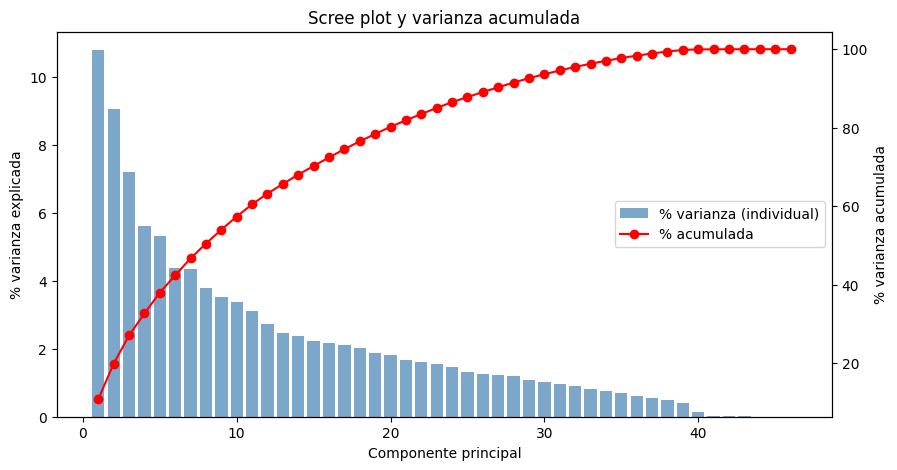

In [6]:
comp_idx = np.arange(1, len(var) + 1)

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.bar(comp_idx, ratio * 100, color="steelblue", alpha=0.7, label="% varianza (individual)")
ax1.set_xlabel("Componente principal")
ax1.set_ylabel("% varianza explicada")

ax2 = ax1.twinx()
ax2.plot(comp_idx, np.cumsum(ratio) * 100, color="red", marker="o", label="% acumulada")
ax2.set_ylabel("% varianza acumulada")
ax2.grid(False)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="center right")
plt.title("Scree plot y varianza acumulada")
plt.show()

## 4. Interpretación de las cargas (φ)

Lo importante es qué variables tienen mayor **valor absoluto** de peso en cada componente. El signo de la componente entera es arbitrario.

In [7]:
loadings_df = pd.DataFrame(
    loadings.T,
    index=X.columns,
    columns=[f"PC{i+1}" for i in range(X.shape[1])],
)

for pc in ["PC1", "PC2", "PC3"]:
    top = loadings_df[pc].reindex(loadings_df[pc].abs().sort_values(ascending=False).index).head(8)
    print(f"\n{pc} — variables con mayor |peso|:")
    print(top.round(3).to_string())


PC1 — variables con mayor |peso|:
hemoglobin    0.383
hematocrit    0.351
mch           0.287
rdw          -0.277
mchc          0.274
iron          0.269
mcv           0.244
albumin       0.228

PC2 — variables con mayor |peso|:
waist            0.358
bmi              0.316
hs_crp           0.265
hba1c            0.262
trig_serum       0.252
ggt              0.248
glucose_serum    0.243
uric_acid        0.229

PC3 — variables con mayor |peso|:
osmolality       0.359
age              0.293
bun              0.287
sodium           0.262
mcv              0.257
rbc             -0.254
mch              0.238
total_protein   -0.226


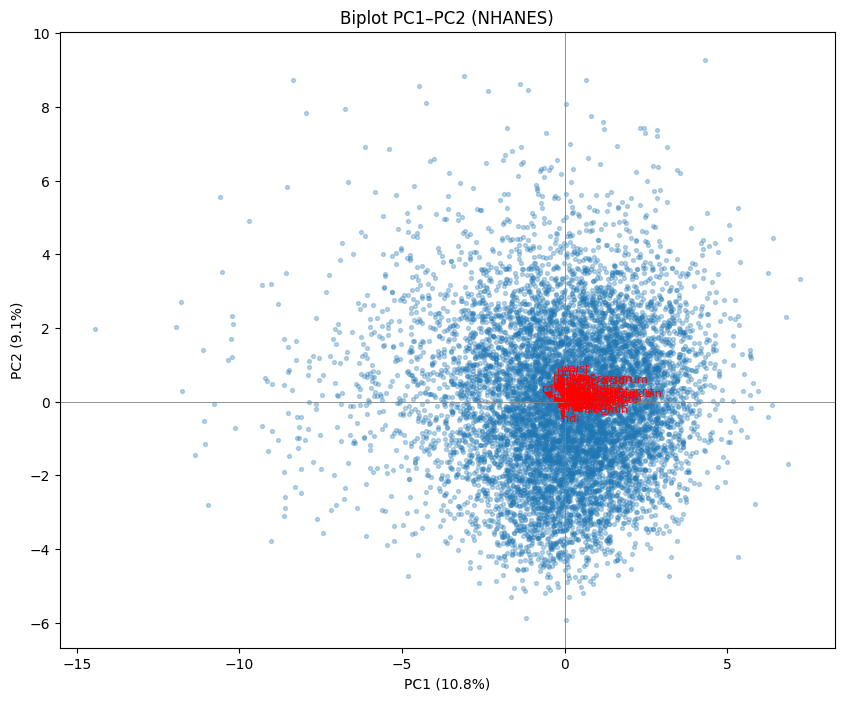

In [8]:
# Biplot: scores (puntos) + cargas escaladas (flechas)
comp = pca.components_.T * np.sqrt(pca.explained_variance_)  # flechas en escala de los scores

fig, ax = plt.subplots(figsize=(10, 8))
ax.scatter(Z[:, 0], Z[:, 1], s=8, alpha=0.3)
for j, name in enumerate(X.columns):
    ax.arrow(0, 0, comp[j, 0], comp[j, 1], color="red", width=0.002,
             head_width=0.15, length_includes_head=True)
    ax.text(comp[j, 0] * 1.12, comp[j, 1] * 1.12, name, color="red", fontsize=8)
ax.axhline(0, color="grey", lw=0.6)
ax.axvline(0, color="grey", lw=0.6)
ax.set_xlabel(f"PC1 ({ratio[0]*100:.1f}%)")
ax.set_ylabel(f"PC2 ({ratio[1]*100:.1f}%)")
ax.set_title("Biplot PC1–PC2 (NHANES)")
plt.show()

## 5. PCR (regresión sobre componentes principales)

Ajustamos `sbp` sobre las `m` primeras componentes. Elegimos `m` por **validación cruzada** (no a ojo). Ojo: PCA no usa `sbp`, así que las primeras componentes no tienen por qué ser las más predictivas.

Antes de modelar, separamos entrenamiento/test y fijamos el esquema de CV que compartirán todos los modelos (mismos folds, misma métrica).

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE)
print("Entrenamiento:", X_train.shape, "| Test:", X_test.shape)

# Esquema compartido por PCR, PLS, Ridge y Lasso
cv = KFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)

Entrenamiento: (7260, 46) | Test: (1815, 46)


In [10]:
pcr_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA()),
    ("model", LinearRegression()),
])
pcr_search = GridSearchCV(
    pcr_pipe,
    param_grid={"pca__n_components": range(1, X.shape[1] + 1)},
    scoring="neg_mean_squared_error",
    cv=cv,
    n_jobs=-1,
)
pcr_search.fit(X_train, y_train)

print("Mejor m (PCR):", pcr_search.best_params_["pca__n_components"])
print("MSE CV (PCR):", -pcr_search.best_score_)

Mejor m (PCR): 40
MSE CV (PCR): 264.60417962095823


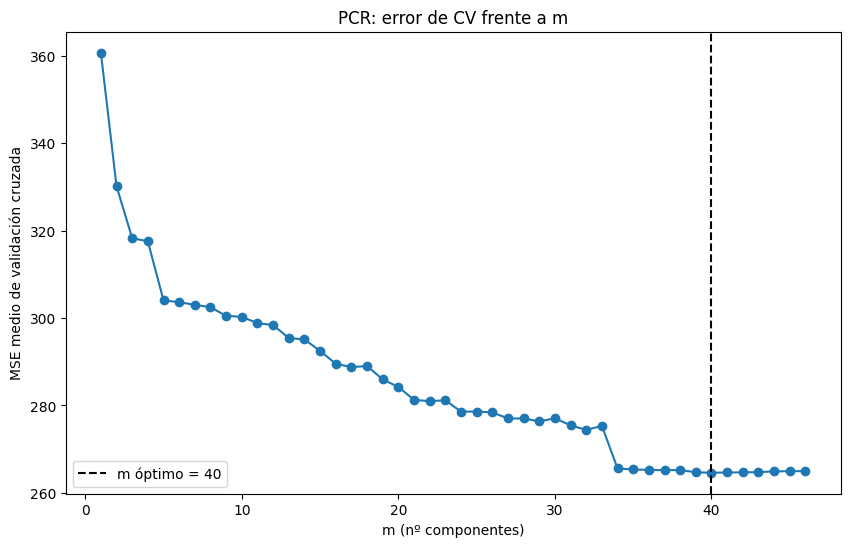

In [11]:
mses_pcr = -pcr_search.cv_results_["mean_test_score"]
m_best_pcr = pcr_search.best_params_["pca__n_components"]

plt.plot(range(1, X.shape[1] + 1), mses_pcr, marker="o")
plt.axvline(m_best_pcr, color="black", linestyle="--", label=f"m óptimo = {m_best_pcr}")
plt.xlabel("m (nº componentes)")
plt.ylabel("MSE medio de validación cruzada")
plt.title("PCR: error de CV frente a m")
plt.legend()
plt.show()

## 6. PLS (supervisado)

PLS calcula las componentes usando también `sbp` (supervisado): la primera dirección da más peso a las variables más correlacionadas con la respuesta. Comparamos PCR y PLS con el **mismo esquema** (mismos folds `cv`, misma métrica).

In [12]:
pls_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("pls", PLSRegression(scale=False)),  # scale=False: ya escala el StandardScaler del pipeline
])
n_pls = 20  # PLS suele necesitar pocas componentes; acotamos la búsqueda
pls_search = GridSearchCV(
    pls_pipe,
    param_grid={"pls__n_components": range(1, n_pls + 1)},
    scoring="neg_mean_squared_error",
    cv=cv,
    n_jobs=-1,
)
pls_search.fit(X_train, y_train)

print("Mejor m (PLS):", pls_search.best_params_["pls__n_components"])
print("MSE CV (PLS):", -pls_search.best_score_)

Mejor m (PLS): 16
MSE CV (PLS): 264.6076990109571


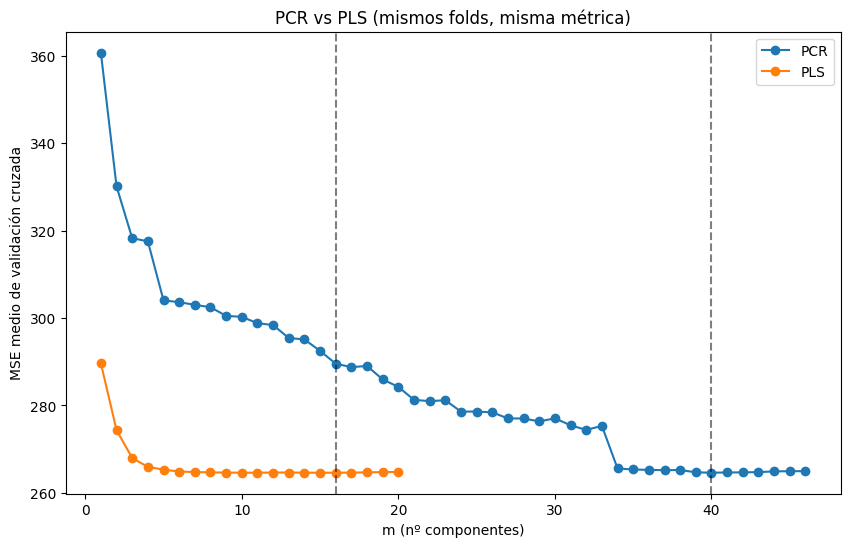

In [13]:
mses_pls = -pls_search.cv_results_["mean_test_score"]
m_best_pls = pls_search.best_params_["pls__n_components"]

plt.plot(range(1, X.shape[1] + 1), mses_pcr, marker="o", label="PCR")
plt.plot(range(1, n_pls + 1), mses_pls, marker="o", label="PLS")
plt.axvline(m_best_pcr, color="black", linestyle="--", alpha=0.5)
plt.axvline(m_best_pls, color="black", linestyle="--", alpha=0.5)
plt.xlabel("m (nº componentes)")
plt.ylabel("MSE medio de validación cruzada")
plt.title("PCR vs PLS (mismos folds, misma métrica)")
plt.legend()
plt.show()

## 7. Comparación final en el conjunto de test

Se compara PCR, PLS y, como referencia, Ridge y Lasso, todos ajustados sobre `X_train` con el mismo `cv` y evaluados **una única vez** en `X_test`.

In [14]:
alphas = np.logspace(-3, 5, 50)

ridge_search = GridSearchCV(
    Pipeline([("scaler", StandardScaler()), ("model", Ridge())]),
    {"model__alpha": alphas}, scoring="neg_mean_squared_error", cv=cv, n_jobs=-1)
lasso_search = GridSearchCV(
    Pipeline([("scaler", StandardScaler()), ("model", Lasso(max_iter=20000))]),
    {"model__alpha": alphas}, scoring="neg_mean_squared_error", cv=cv, n_jobs=-1)

ridge_search.fit(X_train, y_train)
lasso_search.fit(X_train, y_train)

models = {
    "PCR": pcr_search.best_estimator_,
    "PLS": pls_search.best_estimator_,
    "Ridge": ridge_search.best_estimator_,
    "Lasso": lasso_search.best_estimator_,
}

results = []
for name, model in models.items():
    pred = model.predict(X_test)
    results.append({
        "Modelo": name,
        "MSE test": mean_squared_error(y_test, pred),
        "R² test": r2_score(y_test, pred),
    })

results_df = pd.DataFrame(results).sort_values("MSE test")
display(results_df.round(3))

,Modelo,MSE test,R² test
3,Lasso,235.615,0.283
1,PLS,235.931,0.282
0,PCR,235.937,0.282
2,Ridge,236.127,0.282


## 8. Conclusiones (completar con tus resultados)

- **¿Qué recogen PC1/PC2?** Mira las cargas: normalmente PC1 carga sobre el bloque de hemograma (`hemoglobin`, `hematocrit`, `rbc`, `mcv`...) y PC2 sobre lípidos o función hepática. Describe qué variables dominan y qué dimensión biológica representa cada componente.
- **¿Cuántas componentes concentran la varianza?** Indícalo con la curva acumulada (p. ej. "las primeras k componentes explican el X % de la varianza").
- **PCR vs PLS:** ¿quién alcanza menor MSE de CV y con cuántas componentes? PLS suele llegar antes porque usa la respuesta.
- **¿Gana alguno a Ridge/Lasso en test?** Diferencias pequeñas pueden deberse a la variabilidad de la partición.
- **Limitaciones:** no se usan los pesos muestrales (`wt_mec`), no se ha imputado (se descartan filas con NA) y se excluye el panel de ayunas.

> Para integrarlo en la práctica: esta sección corresponde al apartado 5 (PCA) y amplía con PCR/PLS, que se comparan con el apartado 4 (Ridge/Lasso).